# Task 04: End-to-End ML Application with Deployment
## Used Car Price Prediction System
**Devixo Solutions | AI/ML Internship Program**
**Author:** Aman Hameed Ullah
**Dataset:** Vehicle Dataset (Kaggle)

## Table of Contents
1. Data Processing
2. Model Development
3. Hyperparameter Tuning (including cross-validation, feature importance and the final model)
4. Model Saving
5. Preparing the Application Files
6. Conclusion

## 1. Data Processing
### 1.0 Connecting Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Google Drive was mounted so that the notebook can read the dataset and save charts and models in the project folder (`Task_04_AI_ML`).

### 1.1 Importing Libraries

In [2]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

Pandas and NumPy are used for data handling, Matplotlib and Seaborn for charts, and Scikit-learn for the preprocessing pipeline and (later) the models. A scikit-learn `Pipeline` combines all preprocessing steps with the model in one object, which makes the final application simple and safe.

### 1.2 Loading the Dataset

In [3]:
PATH = '/content/drive/MyDrive/Task_04_AI_ML/dataset/car_details.csv'
IMG = '/content/drive/MyDrive/Task_04_AI_ML/images/'
os.makedirs(IMG, exist_ok=True)

df = pd.read_csv(PATH)
raw_rows, raw_cols = df.shape
pd.set_option('display.max_columns', None)
print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB


The dataset contains 8,128 used cars listed on CarDekho (India) with 13 columns: the car name, year, kilometers driven, fuel type, seller type, transmission, number of previous owners, mileage, engine size, maximum power, torque and number of seats. The target is `selling_price` in Indian rupees, so this is a **regression** problem. The columns `mileage`, `engine`, `max_power` and `torque` are stored as text because they contain units (for example "23.4 kmpl", "1248 CC", "74 bhp"); they must be converted to numbers.

### 1.3 Understanding the Target Variable (Selling Price)

count        8128.0
mean       638272.0
std        806253.0
min         29999.0
25%        254999.0
50%        450000.0
75%        675000.0
max      10000000.0
Name: selling_price, dtype: float64
Skewness (raw price): 4.19 | after log transform: 0.22


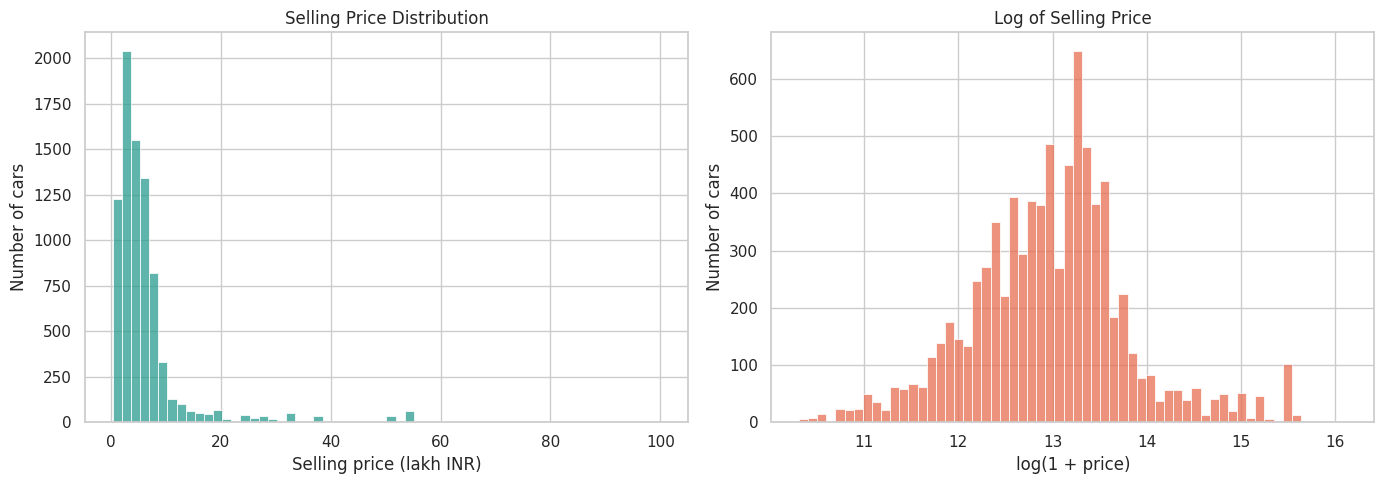

In [4]:
price = df['selling_price']
print(price.describe().round(0))
print("Skewness (raw price):", round(price.skew(), 2), "| after log transform:", round(np.log1p(price).skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(price / 1e5, bins=60, ax=ax[0], color='#2a9d8f')
ax[0].set_title('Selling Price Distribution')
ax[0].set_xlabel('Selling price (lakh INR)'); ax[0].set_ylabel('Number of cars')
sns.histplot(np.log1p(price), bins=60, ax=ax[1], color='#e76f51')
ax[1].set_title('Log of Selling Price')
ax[1].set_xlabel('log(1 + price)'); ax[1].set_ylabel('Number of cars')
plt.tight_layout()
plt.savefig(IMG + 'price_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:** The selling price is strongly right-skewed (skewness 4.19). The median price is 4.5 lakh rupees (450,000) and the mean is about 6.4 lakh, because a small number of luxury cars pull the average up; the most expensive car costs 100 lakh (10,000,000 rupees) and the cheapest about 30,000 rupees. After a log transform the distribution is much more symmetric (skewness 0.22). For this reason the models will be trained on the **logarithm of the price**, and their predictions will be converted back to rupees. This stops the few very expensive cars from dominating the error and usually gives more accurate predictions.

### 1.4 Checking Missing Values

In [5]:
missing = df.isnull().sum()
miss_df = pd.DataFrame({'Missing': missing, 'Percent': (missing / len(df) * 100).round(2)})
display(miss_df[miss_df['Missing'] > 0])
display(df[['mileage', 'engine', 'max_power', 'torque', 'seats']].head())
print(df['fuel'].value_counts(), "\n")
print(df['owner'].value_counts())

,Missing,Percent
mileage,221,2.72
engine,221,2.72
max_power,215,2.65
torque,222,2.73
seats,221,2.72


,mileage,engine,max_power,torque,seats
0,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


fuel
Diesel    4402
Petrol    3631
CNG         57
LPG         38
Name: count, dtype: int64 

owner
First Owner             5289
Second Owner            2105
Third Owner              555
Fourth & Above Owner     174
Test Drive Car             5
Name: count, dtype: int64


**Observation:** Five columns contain missing values (`mileage`, `engine`, `max_power`, `torque` and `seats`), about 2.7% each, and they are mostly missing in the same rows. The columns are first converted to numbers (Section 1.6). The remaining missing values are then filled with the **median** inside the pipeline (Section 1.12), after the train-test split. The median is used because it is not affected by extreme values, and fitting it on the training data only avoids data leakage.

### 1.5 Removing Duplicate Records

In [6]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates after removal:", df.duplicated().sum())
print("Shape:", df.shape)

Duplicate rows: 1202
Duplicates after removal: 0
Shape: (6926, 13)


**Observation:** The dataset contained 1,202 duplicate rows (identical in every column), which is 14.79% of the data. They were removed because duplicates give extra weight to the same car and could appear in both the training and the test set, which would make the test results look better than they really are. After removal 6,926 rows remain.

### 1.6 Converting Text Columns with Units to Numbers

In [7]:
for col in ['mileage', 'engine', 'max_power']:
    df[col] = pd.to_numeric(df[col].astype(str).str.extract(r'(\d+\.?\d*)')[0], errors='coerce')

df = df.drop(columns='torque')
display(df[['mileage', 'engine', 'max_power', 'seats']].describe().round(2))
print(df.isnull().sum()[df.isnull().sum() > 0])

,mileage,engine,max_power,seats
count,6718.00,6718.00,6720.00,6718.00
mean,19.47,1430.89,87.73,5.43
std,4.05,493.49,31.77,0.98
min,0.00,624.00,0.00,2.00
25%,16.80,1197.00,67.10,5.00
50%,19.44,1248.00,81.83,5.00
75%,22.50,1498.00,100.00,5.00
max,42.00,3604.00,400.00,14.00


mileage      208
engine       208
max_power    206
seats        208
dtype: int64


**Observation:** After the conversion, `mileage` and `engine` have 208 missing values each (after removing the duplicates), `max_power` has 206 and `seats` has 208. The summary statistics also show impossible values: the minimum `mileage` and the minimum `max_power` are 0, which are handled in Section 1.8. Engine sizes range from 624 to 3,604 cc and the maximum power is 400 bhp, which are real values for small hatchbacks and luxury cars.

The numbers were extracted from the text: "23.4 kmpl" became 23.4, "1248 CC" became 1248 and "74 bhp" became 74. Values that were blank or contained no number became missing values, which are filled later. The column `torque` was dropped because its text format is inconsistent (different units such as Nm and kgm and different rpm formats), and engine size and power already describe the strength of the car. Note that the mileage of CNG and LPG cars is given in km/kg instead of km/l; this affects only a small share of the cars, and the model can tell them apart through the `fuel` column.

### 1.7 Detecting Outliers

,Lower Bound,Upper Bound,Outliers,Outlier %
selling_price,-325250.0,1208750.0,328.0,4.74
km_driven,-50000.0,190000.0,167.0,2.41
mileage,8.3,31.0,21.0,0.31
engine,745.5,1949.5,1207.0,17.97
max_power,17.7,149.4,307.0,4.57
seats,5.0,5.0,1464.0,21.79


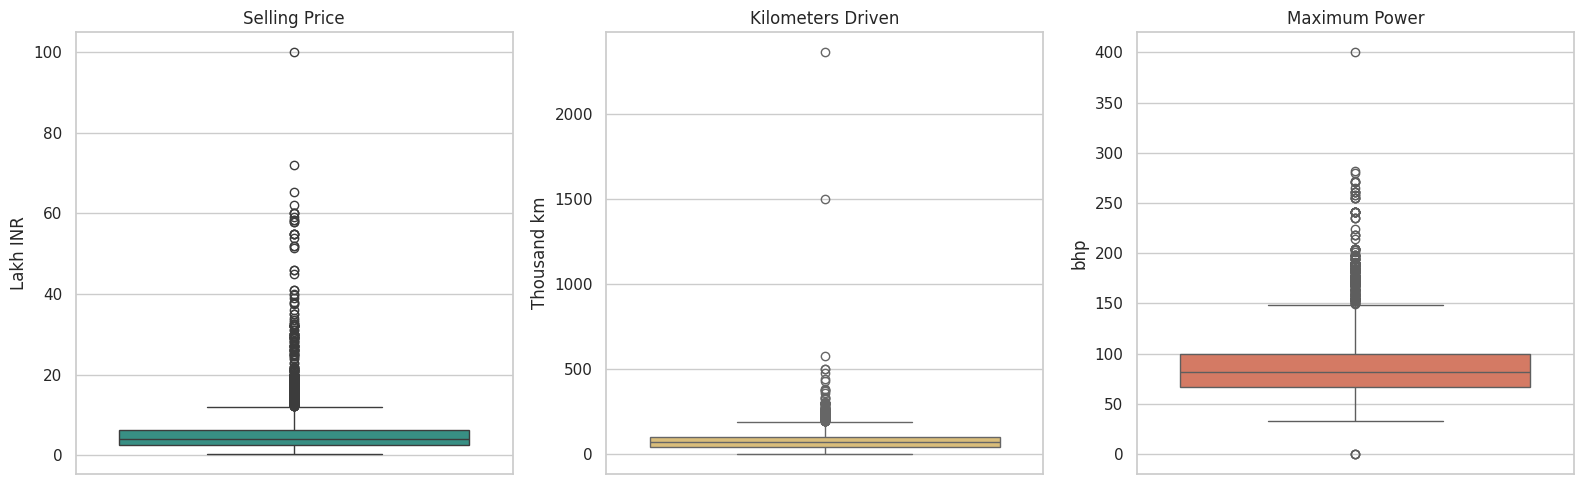

Test drive cars: 5
km_driven above 500,000: 3 | maximum km_driven: 2360457
Mileage equal to 0: 15


In [8]:
def iqr_summary(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((s < low) | (s > high)).sum()
    return pd.Series({'Lower Bound': round(low, 1), 'Upper Bound': round(high, 1),
                      'Outliers': n, 'Outlier %': round(n / len(s) * 100, 2)})

check_cols = ['selling_price', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
out_df = pd.DataFrame({c: iqr_summary(df[c].dropna()) for c in check_cols}).T
display(out_df)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
sns.boxplot(y=df['selling_price'] / 1e5, ax=ax[0], color='#2a9d8f')
ax[0].set_title('Selling Price'); ax[0].set_ylabel('Lakh INR')
sns.boxplot(y=df['km_driven'] / 1000, ax=ax[1], color='#e9c46a')
ax[1].set_title('Kilometers Driven'); ax[1].set_ylabel('Thousand km')
sns.boxplot(y=df['max_power'], ax=ax[2], color='#e76f51')
ax[2].set_title('Maximum Power'); ax[2].set_ylabel('bhp')
plt.tight_layout()
plt.savefig(IMG + 'outlier_boxplots.png', dpi=300, bbox_inches='tight')
plt.show()

print("Test drive cars:", (df['owner'] == 'Test Drive Car').sum())
print("km_driven above 500,000:", (df['km_driven'] > 500000).sum(), "| maximum km_driven:", df['km_driven'].max())
print("Mileage equal to 0:", (df['mileage'] == 0).sum())

Outliers were detected with the **IQR method**: a value is an outlier if it is below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR. The table and the box plots show outliers in `selling_price` (328 cars, 4.74%), `km_driven` (167 cars, 2.41%), `mileage` (21 cars, 0.31%) and `max_power` (307 cars, 4.57%). `engine` (17.97%) and `seats` (21.79%) show a high share only because most cars have the same few values (most cars have 5 seats, so the IQR is zero and the method marks every other seat count as an outlier), so these two columns were not treated as outliers. Not every outlier is an error, so each case was judged separately:
- **Selling price, engine size and power:** very expensive cars (up to 100 lakh) and powerful engines (up to 400 bhp) are real luxury and sports cars. They were **kept**, and the log transform of the target reduces their influence.
- **Impossible or irrelevant values:** 5 cars were sold as "Test Drive Car" (not a normal resale), 3 cars show more than 500,000 km (the maximum is 2,360,457 km, which is an entry error), 15 cars have a mileage of 0 and 3 cars have a maximum power of 0. These are handled in the next step.

### 1.8 Handling Outliers and Invalid Values

In [9]:
before = len(df)
df = df[(df['owner'] != 'Test Drive Car') & (df['km_driven'] <= 500000)].reset_index(drop=True)
print("Mileage equal to 0:", (df['mileage'] == 0).sum())
print("Max power equal to 0:", (df['max_power'] == 0).sum())
df.loc[df['mileage'] == 0, 'mileage'] = np.nan        # a mileage of 0 is not real: treat as missing
df.loc[df['max_power'] == 0, 'max_power'] = np.nan    # a power of 0 is not real: treat as missing
print("Rows removed:", before - len(df))
print("Shape:", df.shape)

Mileage equal to 0: 15
Max power equal to 0: 3
Rows removed: 8
Shape: (6918, 12)


Test-drive cars (5) and cars with more than 500,000 km (3) were removed (8 rows in total), leaving 6,918 rows, because they are not typical used-car listings or are data-entry errors. Cars with a mileage of 0 (15) or a maximum power of 0 (3) were not removed; the impossible value was set to missing and will be filled with the median in the pipeline, so the other information of these cars is not lost. Genuine luxury cars were kept, so the application can also estimate the price of expensive cars.

### 1.9 Feature Engineering

In [10]:
REF_YEAR = int(df['year'].max())          # the newest year in the data is used as the reference year
print("Reference year:", REF_YEAR)

def get_brand(name):
    name = name.strip()
    return 'Land Rover' if name.startswith('Land Rover') else name.split()[0]

owner_map = {'First Owner': 1, 'Second Owner': 2, 'Third Owner': 3, 'Fourth & Above Owner': 4}

df['car_age'] = REF_YEAR - df['year']
df['brand'] = df['name'].apply(get_brand)
df['owner_num'] = df['owner'].map(owner_map)
df['km_per_year'] = (df['km_driven'] / df['car_age'].clip(lower=1)).round(0)
df['power_per_litre'] = (df['max_power'] / df['engine'] * 1000).round(2)

df = df.drop(columns=['name', 'year', 'owner'])
print("Number of brands:", df['brand'].nunique())
print(df['brand'].value_counts().head(10))
display(df[['car_age', 'km_per_year', 'power_per_litre', 'owner_num']].describe().round(2))

df.to_csv('/content/drive/MyDrive/Task_04_AI_ML/dataset/cleaned_car_data.csv', index=False)
print("Cleaned data saved:", df.shape)

Reference year: 2020
Number of brands: 32
brand
Maruti        2164
Hyundai       1266
Mahindra       722
Tata           647
Ford           361
Honda          361
Toyota         357
Chevrolet      216
Renault        206
Volkswagen     173
Name: count, dtype: int64


,car_age,km_per_year,power_per_litre,owner_num
count,6918.00,6918.00,6709.00,6918.00
mean,6.58,13216.25,62.52,1.51
std,4.08,9334.49,12.27,0.74
min,0.00,0.00,21.31,1.00
25%,3.00,7381.25,58.74,1.00
50%,6.00,11111.00,64.25,1.00
75%,9.00,16667.00,68.39,2.00
max,37.00,120000.00,203.15,4.00


Cleaned data saved: (6918, 14)


Five new features were created, and the original columns they replace were dropped:
- `car_age`: the reference year (the newest year in the data) minus the manufacturing year. Age is more meaningful for price than the year itself, and the application can calculate it from the year entered by the user.
- `brand`: the first word of the car name (for example "Maruti" or "Land Rover"). The full name has thousands of different values and is too detailed, while the brand captures the price level of the manufacturer.
- `owner_num`: the owner category as a number (1 = first owner to 4 = fourth or more owners), because the owners have a natural order.
- `km_per_year`: kilometers driven divided by the age, which shows how intensively the car was used.
- `power_per_litre`: horsepower per liter of engine size, which separates performance cars from ordinary ones.

The cleaned dataset was saved, so that the Streamlit application can use it for its charts page.

The data contains 32 brands; Maruti (2,164 cars), Hyundai (1,266), Mahindra (722) and Tata (647) are the most frequent. The cleaned dataset (6,918 rows) was saved for the Streamlit application.

### 1.10 Exploring the Data Visually

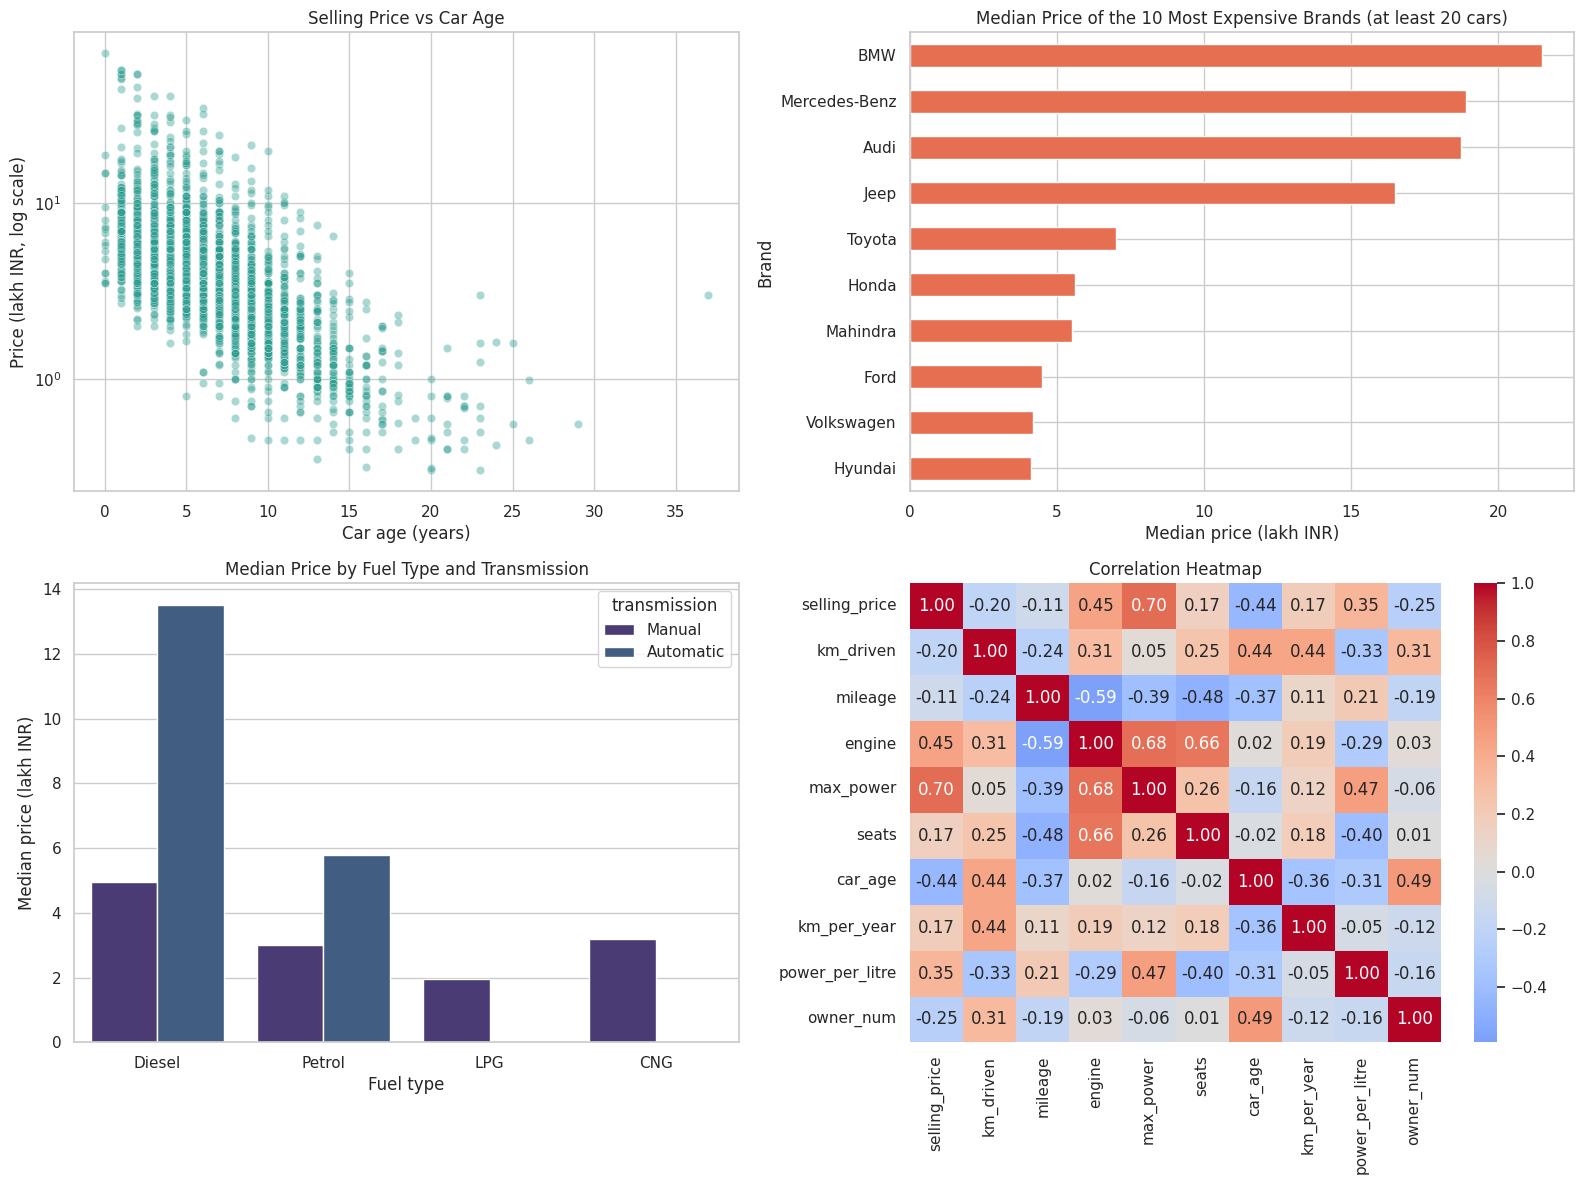

In [11]:
plot_df = df.assign(price_lakh=df['selling_price'] / 1e5)
fig, ax = plt.subplots(2, 2, figsize=(16, 12))

sns.scatterplot(data=plot_df.sample(3000, random_state=42), x='car_age', y='price_lakh',
                alpha=0.4, ax=ax[0, 0], color='#2a9d8f')
ax[0, 0].set_yscale('log')
ax[0, 0].set_title('Selling Price vs Car Age')
ax[0, 0].set_xlabel('Car age (years)'); ax[0, 0].set_ylabel('Price (lakh INR, log scale)')

big = plot_df['brand'].value_counts()
big = big[big >= 20].index
top_brands = plot_df[plot_df['brand'].isin(big)].groupby('brand')['price_lakh'].median().sort_values(ascending=False).head(10)
top_brands[::-1].plot(kind='barh', color='#e76f51', ax=ax[0, 1])
ax[0, 1].set_title('Median Price of the 10 Most Expensive Brands (at least 20 cars)')
ax[0, 1].set_xlabel('Median price (lakh INR)'); ax[0, 1].set_ylabel('Brand')

sns.barplot(data=plot_df, x='fuel', y='price_lakh', hue='transmission', estimator=np.median,
            errorbar=None, ax=ax[1, 0])
ax[1, 0].set_title('Median Price by Fuel Type and Transmission')
ax[1, 0].set_xlabel('Fuel type'); ax[1, 0].set_ylabel('Median price (lakh INR)')

corr_cols = ['selling_price', 'km_driven', 'mileage', 'engine', 'max_power', 'seats',
             'car_age', 'km_per_year', 'power_per_litre', 'owner_num']
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[1, 1])
ax[1, 1].set_title('Correlation Heatmap')

plt.tight_layout()
plt.savefig(IMG + 'eda_overview.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:**
- **Price and age:** the price falls clearly as the car gets older (correlation with car age: -0.44). On the log scale the points follow a downward band, and cars older than about 15 years are almost always cheap.
- **Brand:** luxury brands are far more expensive than the rest: BMW has the highest median price (about 21 lakh), followed by Mercedes-Benz and Audi (about 19 lakh each) and Jeep (about 16 lakh). Common brands such as Toyota, Honda, Mahindra, Ford, Volkswagen and Hyundai have median prices between 4 and 7 lakh. The brand is therefore an important feature.
- **Fuel and transmission:** automatic cars are much more expensive than manual cars of the same fuel: for diesel about 13 lakh against 5 lakh, and for petrol about 6 lakh against 3 lakh. Diesel cars cost more than petrol cars.
- **Correlations:** the selling price is most strongly related to `max_power` (0.70), followed by `engine` (0.45), `car_age` (-0.44, negative) and `power_per_litre` (0.35, an engineered feature). More kilometers (-0.20) and more owners (-0.25) lower the price. Engine size and power are strongly related to each other (0.68).

### 1.11 Splitting into Training and Testing Sets

In [12]:
X = df.drop(columns='selling_price')
y = df['selling_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Mean price train:", round(y_train.mean()), "| test:", round(y_test.mean()))

Train: (5534, 13) | Test: (1384, 13)
Mean price train: 513397 | test: 518941


The data was split into 80% for training and 20% for testing. The models learn from the training set and are evaluated on the test set, which they have never seen. `random_state=42` makes the split reproducible. The split was done **before** imputing, scaling and encoding, so that these steps learn from the training data only.

The mean price is similar in the training set (513,397 rupees) and in the test set (518,941 rupees), so both parts are representative.

### 1.12 Building the Preprocessing Pipeline (Imputation, Scaling and Encoding)

In [13]:
num_features = ['km_driven', 'mileage', 'engine', 'max_power', 'seats',
                'car_age', 'km_per_year', 'power_per_litre', 'owner_num']
cat_features = ['fuel', 'seller_type', 'transmission', 'brand']

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scaler', StandardScaler())]), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])
preprocessor.set_output(transform='pandas')

X_train_p = preprocessor.fit_transform(X_train)     # learn only from the training data
X_test_p = preprocessor.transform(X_test)

print("Shape after preprocessing - train:", X_train_p.shape, "| test:", X_test_p.shape)
print("Missing values left - train:", X_train_p.isnull().sum().sum(), "| test:", X_test_p.isnull().sum().sum())
display(X_train_p.head())

Shape after preprocessing - train: (5534, 49) | test: (1384, 49)
Missing values left - train: 0 | test: 0


,num__km_driven,num__mileage,num__engine,num__max_power,num__seats,num__car_age,num__km_per_year,num__power_per_litre,num__owner_num,cat__fuel_CNG,cat__fuel_Diesel,cat__fuel_LPG,cat__fuel_Petrol,cat__seller_type_Dealer,cat__seller_type_Individual,cat__seller_type_Trustmark Dealer,cat__transmission_Automatic,cat__transmission_Manual,cat__brand_Ambassador,cat__brand_Ashok,cat__brand_Audi,cat__brand_BMW,cat__brand_Chevrolet,cat__brand_Daewoo,cat__brand_Datsun,cat__brand_Fiat,cat__brand_Force,cat__brand_Ford,cat__brand_Honda,cat__brand_Hyundai,cat__brand_Isuzu,cat__brand_Jaguar,cat__brand_Jeep,cat__brand_Kia,cat__brand_Land Rover,cat__brand_MG,cat__brand_Mahindra,cat__brand_Maruti,cat__brand_Mercedes-Benz,cat__brand_Mitsubishi,cat__brand_Nissan,cat__brand_Opel,cat__brand_Peugeot,cat__brand_Renault,cat__brand_Skoda,cat__brand_Tata,cat__brand_Toyota,cat__brand_Volkswagen,cat__brand_Volvo
26,-0.942591,1.328328,-1.288931,-1.281738,-0.431053,-0.882077,-0.413028,-0.258368,-0.694950,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3484,-1.108084,0.891248,0.150574,0.365844,-0.431053,-1.371441,0.724995,0.288826,-0.694950,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
63,-0.280623,0.446454,-0.058585,0.040538,-0.431053,0.096653,-0.494323,0.084452,-0.694950,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1044,-0.073758,0.325614,0.074703,-0.717235,-0.431053,0.341335,-0.475226,-1.488729,0.651166,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2594,-1.066710,-0.908495,-0.116001,2.312581,-0.431053,-1.371441,0.938367,4.483426,-0.694950,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


All preprocessing is combined in one `ColumnTransformer`:
- **Numerical columns:** missing values are filled with the median, and the values are standardized (mean 0, standard deviation 1). Scaling is needed for linear models, while tree-based models are not affected by it.
- **Categorical columns** (fuel, seller type, transmission and brand): converted with one-hot encoding, which creates a separate 0/1 column for each category. `handle_unknown='ignore'` keeps the pipeline safe if the user selects a brand that was not in the training data.

The pipeline was fitted on the training data only and then applied to the test data. After preprocessing there are 49 features: 9 numerical columns, 4 fuel types, 3 seller types, 2 transmission types and 31 brands. The data contains 32 brands, so one brand appears only in the test set; for such a brand all brand columns are 0, which shows why handling unknown categories matters. There are no missing values left and all features are numeric.

### 1.13 Verifying the Prepared Data

In [14]:
print("Raw data:", raw_rows, "rows x", raw_cols, "columns")
print("After cleaning:", df.shape[0], "rows x", df.shape[1], "columns (includes the engineered features)")
print("Train / test rows:", len(X_train), "/", len(X_test))
print("Features after encoding:", X_train_p.shape[1])
print("Brands:", df['brand'].nunique(), "| Fuel types:", df['fuel'].unique().tolist())

Raw data: 8128 rows x 13 columns
After cleaning: 6918 rows x 14 columns (includes the engineered features)
Train / test rows: 5534 / 1384
Features after encoding: 49
Brands: 32 | Fuel types: ['Diesel', 'Petrol', 'LPG', 'CNG']


**Summary of data processing:** the text columns were converted to numbers, duplicates, test-drive cars and impossible kilometer values were removed, outliers were analyzed with the IQR method (genuine luxury cars were kept), five features were engineered, and the data was split 80/20. Missing values, scaling and encoding are handled by one pipeline that is fitted on the training data only. The data is now ready for model development.

## 2. Model Development
### 2.0 Importing Models and Creating the Training Functions

In [15]:
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             mean_absolute_percentage_error)

fitted, train_time = {}, {}

def build_model(regressor):
    """Preprocessing + model; trained on log(price) but predicts the price in rupees."""
    pipe = Pipeline([('preprocess', clone(preprocessor)), ('model', regressor)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MAE': mean_absolute_error(y_true, y_pred), 'MSE': mse, 'RMSE': np.sqrt(mse),
            'R2': r2_score(y_true, y_pred),
            'R2 (log price)': r2_score(np.log1p(y_true), np.log1p(y_pred)),
            'MAPE (%)': mean_absolute_percentage_error(y_true, y_pred) * 100}

def train_model(name, regressor):
    model = build_model(regressor)
    start = time.time()
    model.fit(X_train, y_train)
    train_time[name] = round(time.time() - start, 2)
    fitted[name] = model
    print(f"{name}: trained in {train_time[name]} s | train R2 = {r2_score(y_train, model.predict(X_train)):.4f}"
          f" | test R2 = {r2_score(y_test, model.predict(X_test)):.4f}")

Five regression models from different algorithm families are trained: Linear Regression, Decision Tree, Random Forest, Gradient Boosting and XGBoost. Each model is a complete pipeline (imputation, scaling, encoding and the model) wrapped in a `TransformedTargetRegressor`. This wrapper trains the model on the **logarithm of the price** (Section 1.3) and converts the prediction back to rupees automatically, so every model receives raw car data and returns a price in rupees. This is exactly what the final application needs. The function `evaluate` calculates the four required metrics on the price in rupees, plus the R² on the log scale and the MAPE (the average percentage error), which is easy to understand.

### 2.1 Linear Regression

In [16]:
train_model('Linear Regression', LinearRegression())

Linear Regression: trained in 0.11 s | train R2 = 0.9131 | test R2 = 0.8426


**Observation:** Linear Regression reached a test R² of 0.8426 (training R² 0.9131). It is the fastest model and serves as the baseline that the other models must beat.

Linear Regression predicts the (log) price as a weighted sum of the features. It is simple, fast and easy to interpret, and it serves as the baseline model. It can only learn straight-line relationships, so it may miss complex effects such as the interaction between brand, age and engine power. It uses the scaled numerical features from the pipeline.

### 2.2 Decision Tree

In [17]:
train_model('Decision Tree', DecisionTreeRegressor(random_state=42))
dt = fitted['Decision Tree'].regressor_.named_steps['model']
print("Tree depth:", dt.get_depth(), "| Number of leaves:", dt.get_n_leaves())

Decision Tree: trained in 0.13 s | train R2 = 0.9992 | test R2 = 0.8473
Tree depth: 29 | Number of leaves: 4997


**Observation:** The Decision Tree reached a training R² of 0.9992 but a test R² of only 0.8473. Its depth is 29 with 4,997 leaves for only 5,534 training cars, so it has almost memorized every training car (overfitting).

A Decision Tree splits the cars with yes/no questions (for example "is the maximum power above 100 bhp?") until it reaches a price estimate. It can learn non-linear patterns and is easy to understand. This baseline tree has no depth limit, so it can grow very deep and memorize the training cars (overfitting); its depth can be controlled by hyperparameter tuning in Part 3.

### 2.3 Random Forest

In [18]:
train_model('Random Forest', RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))

Random Forest: trained in 8.04 s | train R2 = 0.9805 | test R2 = 0.8982


**Observation:** The Random Forest has a test R² of 0.8982, much higher than the single tree (0.8473), which shows the benefit of averaging many trees. It still shows a clear gap to its training R² (0.9805), so it overfits somewhat, and it is the slowest of the five models to train.

A Random Forest builds many decision trees (here 200), each trained on a random sample of the cars and a random subset of the features, and averages their predictions. Because the errors of individual trees partly cancel each other, the forest is more accurate and less prone to overfitting than one tree. It also provides feature importance. The disadvantages are a longer training time and a larger saved model.

### 2.4 Gradient Boosting

In [19]:
train_model('Gradient Boosting', GradientBoostingRegressor(random_state=42))

Gradient Boosting: trained in 1.14 s | train R2 = 0.9239 | test R2 = 0.8954


**Observation:** Gradient Boosting reached a test R² of 0.8954 and has the smallest gap between training and test R² (0.9239 and 0.8954) among the tree-based models. It also trained much faster than the Random Forest.

Gradient Boosting builds shallow trees one after another, and each new tree tries to correct the errors of the previous trees. This step-by-step improvement often gives very accurate models on tabular data. Training is slower than for XGBoost because it cannot be parallelized.

### 2.5 XGBoost

In [20]:
train_model('XGBoost', XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=5,
                                    random_state=42, n_jobs=-1))

XGBoost: trained in 0.61 s | train R2 = 0.9787 | test R2 = 0.9118


**Observation:** XGBoost reached the highest test R² (0.9118) and trained in a few seconds, much faster than the Random Forest, so it is the most accurate model at this stage.

XGBoost is an optimized and regularized implementation of gradient boosting. It is fast, handles tables efficiently and uses regularization to reduce overfitting. The settings (300 trees, learning rate 0.1, depth 5) are reasonable defaults that will be improved by tuning in Part 3.

### 2.6 Evaluating the Models on the Test Set

In [21]:
rows, preds = [], {}
for name, model in fitted.items():
    p = model.predict(X_test)
    preds[name] = p
    m = evaluate(y_test, p)
    m['Model'] = name
    m['Train Time (s)'] = train_time[name]
    m['Train R2'] = r2_score(y_train, model.predict(X_train))
    rows.append(m)

results_df = pd.DataFrame(rows).set_index('Model')[
    ['Train Time (s)', 'Train R2', 'MAE', 'MSE', 'RMSE', 'R2', 'R2 (log price)', 'MAPE (%)']]
results_df = results_df.sort_values('R2', ascending=False)
display(results_df.style.format({'Train Time (s)': '{:.2f}', 'Train R2': '{:.4f}', 'MAE': '{:,.0f}',
                                 'MSE': '{:,.0f}', 'RMSE': '{:,.0f}', 'R2': '{:.4f}',
                                 'R2 (log price)': '{:.4f}', 'MAPE (%)': '{:.2f}'}))
results_df.to_csv(IMG + 'baseline_results.csv')

,Train Time (s),Train R2,MAE,MSE,RMSE,R2,R2 (log price),MAPE (%)
Model,,,,,,,,
XGBoost,0.61,0.9787,"75,273","20,949,248,000","144,739",0.9118,0.9143,16.24
Random Forest,8.04,0.9805,"79,016","24,170,435,021","155,468",0.8982,0.9051,17.11
Gradient Boosting,1.14,0.9239,"84,103","24,839,257,790","157,605",0.8954,0.9072,17.68
Decision Tree,0.13,0.9992,"99,065","36,257,694,504","190,415",0.8473,0.8390,22.26
Linear Regression,0.11,0.9131,"98,548","37,354,663,779","193,274",0.8426,0.8803,20.42


**Observation:**
- XGBoost is the best model on every metric: MAE 75,273, MSE 20,949,248,000, RMSE 144,739 and R² 0.9118. Its average error is about 0.75 lakh rupees, which is about 14.5% of the mean test price (518,941 rupees), and its average percentage error (MAPE) is 16.24%.
- Random Forest (R² 0.8982) and Gradient Boosting (R² 0.8954) follow with similar results. On the log scale Gradient Boosting (0.9072) is slightly better than Random Forest (0.9051).
- The Decision Tree and Linear Regression are the weakest models (R² 0.8473 and 0.8426; RMSE about 190,000 to 193,000 rupees). The Decision Tree overfits strongly (training R² 0.9992), while Linear Regression has a better log-scale R² (0.8803) than the tree (0.8390), which means that it is more reliable for cheap and medium-priced cars.
- The RMSE is about twice as large as the MAE for all models, because a few expensive cars have large errors that RMSE punishes strongly.
- All the boosting and forest models explain about 90% of the variation in prices, and there is still a gap between training and test R², so tuning in Part 3 should help.

All models were evaluated on the test set (1,384 cars) that they have never seen, with the four required regression metrics (in rupees):
- **MAE** (Mean Absolute Error): the average size of the error.
- **MSE** (Mean Squared Error): the average of the squared errors; it punishes large errors strongly.
- **RMSE** (Root Mean Squared Error): the square root of MSE, again in rupees, so it is easy to interpret.
- **R² Score**: the share of the variation in prices that the model explains (1.0 is perfect, 0 means no better than predicting the average).

The R² on the log scale and the MAPE (average percentage error) are shown as additional information. The gap between the training R² and the test R² shows overfitting.

### 2.7 Actual vs Predicted Prices and Model Comparison

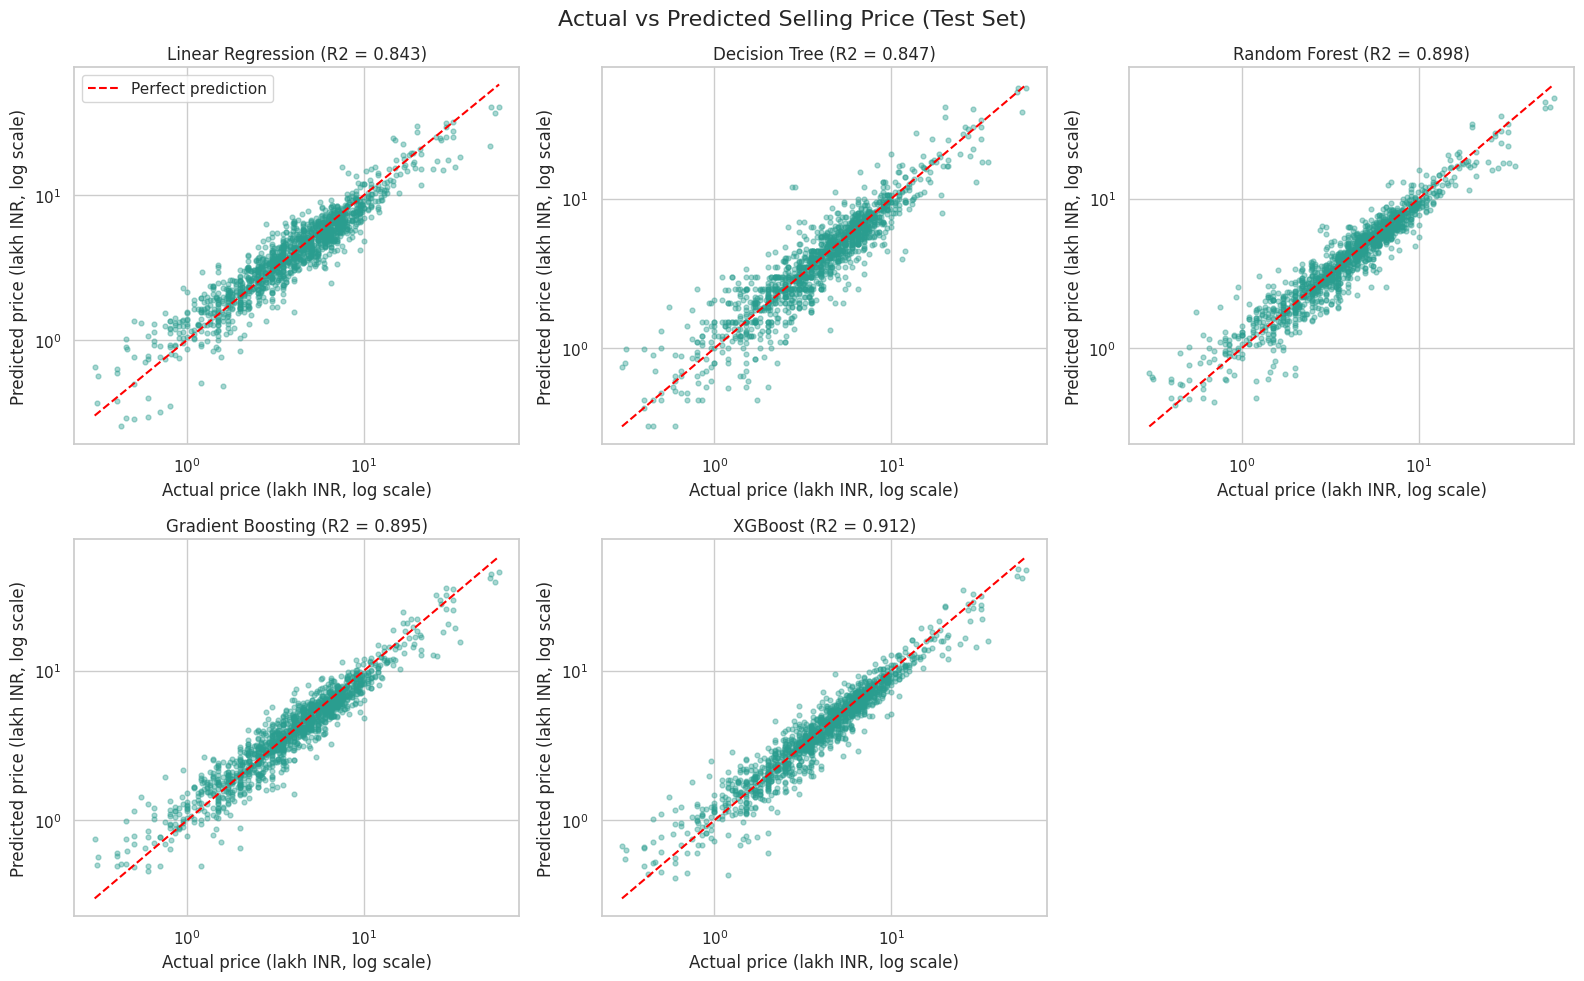

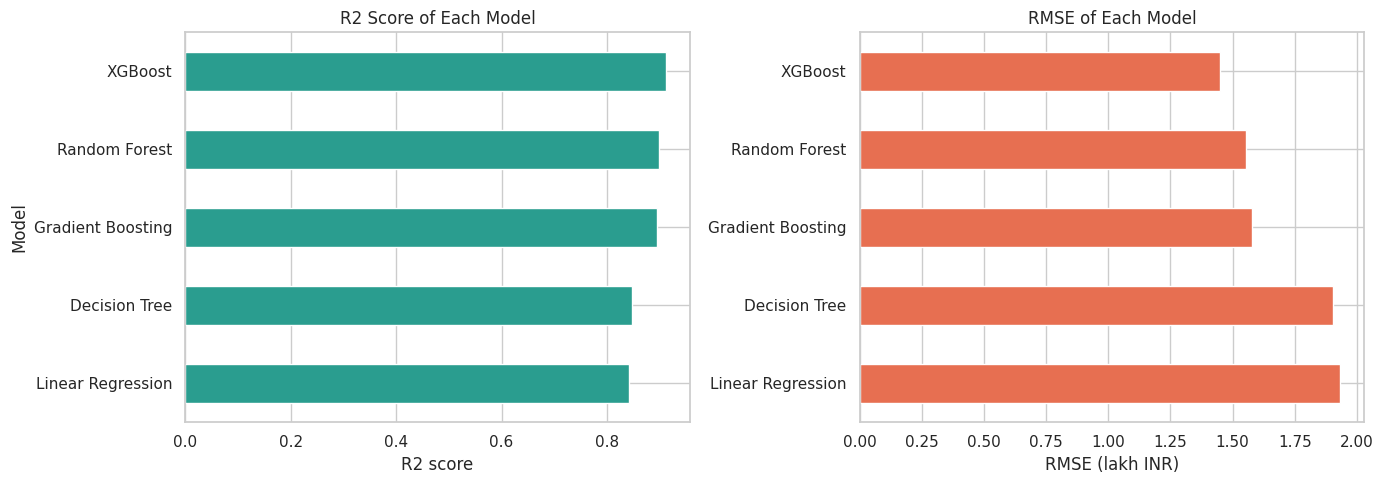

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (name, p) in zip(axes.ravel(), preds.items()):
    ax.scatter(y_test / 1e5, p / 1e5, alpha=0.4, s=12, color='#2a9d8f')
    lims = [y_test.min() / 1e5, y_test.max() / 1e5]
    ax.plot(lims, lims, 'r--', label='Perfect prediction')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_title(f"{name} (R2 = {r2_score(y_test, p):.3f})")
    ax.set_xlabel('Actual price (lakh INR, log scale)'); ax.set_ylabel('Predicted price (lakh INR, log scale)')
axes.ravel()[0].legend()
axes.ravel()[-1].axis('off')
plt.suptitle('Actual vs Predicted Selling Price (Test Set)', fontsize=16)
plt.tight_layout()
plt.savefig(IMG + 'actual_vs_predicted_baseline.png', dpi=300, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
results_df['R2'].sort_values().plot(kind='barh', color='#2a9d8f', ax=ax[0])
ax[0].set_title('R2 Score of Each Model'); ax[0].set_xlabel('R2 score'); ax[0].set_ylabel('Model')
(results_df['RMSE'] / 1e5).sort_values(ascending=False).plot(kind='barh', color='#e76f51', ax=ax[1])
ax[1].set_title('RMSE of Each Model'); ax[1].set_xlabel('RMSE (lakh INR)'); ax[1].set_ylabel('')
plt.tight_layout()
plt.savefig(IMG + 'model_comparison_baseline.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:** In the actual-vs-predicted charts (log scale) the points of XGBoost, Random Forest and Gradient Boosting lie closer to the red "perfect prediction" line than those of Linear Regression and the Decision Tree, which are more scattered, especially for cheap cars. The comparison charts confirm that XGBoost has the highest R² and the lowest RMSE (about 1.45 lakh rupees), while the Decision Tree and Linear Regression have the highest RMSE (about 1.9 lakh rupees).

## 3. Hyperparameter Tuning
### 3.1 Cross-Validation of the Baseline Models

Linear Regression done in 3.0 s
Decision Tree done in 0.5 s
Random Forest done in 32.2 s
Gradient Boosting done in 3.8 s
XGBoost done in 2.4 s


,CV R2,CV R2 Std,CV MAE,CV RMSE
Model,,,,
Linear Regression,0.9094,0.0122,"88,342","152,427"
Random Forest,0.8920,0.0320,"78,483","166,224"
Gradient Boosting,0.8915,0.0503,"81,756","164,681"
XGBoost,0.8748,0.0684,"76,608","175,772"
Decision Tree,0.8353,0.0488,"99,749","203,567"


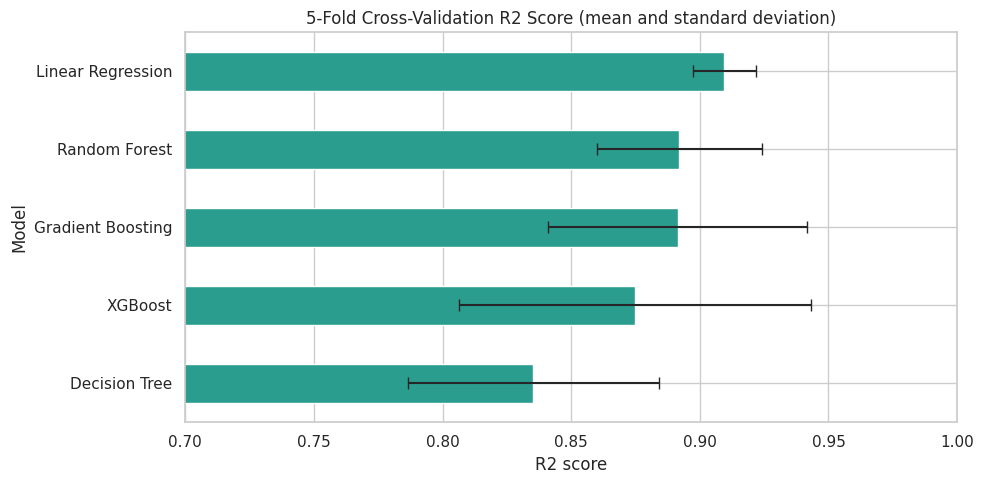

In [23]:
from sklearn.model_selection import KFold, cross_validate, GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.inspection import permutation_importance

cv5 = KFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, model in fitted.items():
    start = time.time()
    res = cross_validate(model, X_train, y_train, cv=cv5, n_jobs=-1,
                         scoring={'r2': 'r2', 'mae': 'neg_mean_absolute_error',
                                  'rmse': 'neg_root_mean_squared_error'})
    cv_rows.append({'Model': name, 'CV R2': res['test_r2'].mean(), 'CV R2 Std': res['test_r2'].std(),
                    'CV MAE': -res['test_mae'].mean(), 'CV RMSE': -res['test_rmse'].mean()})
    print(f"{name} done in {round(time.time() - start, 1)} s")

cv_df = pd.DataFrame(cv_rows).set_index('Model').sort_values('CV R2', ascending=False)
display(cv_df.style.format({'CV R2': '{:.4f}', 'CV R2 Std': '{:.4f}', 'CV MAE': '{:,.0f}', 'CV RMSE': '{:,.0f}'}))
cv_df.to_csv(IMG + 'cross_validation_results.csv')

order = cv_df['CV R2'].sort_values()
order.plot(kind='barh', xerr=cv_df['CV R2 Std'].reindex(order.index), color='#2a9d8f',
           figsize=(10, 5), capsize=4)
plt.xlim(0.7, 1.0)
plt.title('5-Fold Cross-Validation R2 Score (mean and standard deviation)')
plt.xlabel('R2 score'); plt.ylabel('Model')
plt.tight_layout()
plt.savefig(IMG + 'cross_validation_r2.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:**
- In 5-fold cross-validation Linear Regression has the best R² (0.9094) and the lowest RMSE (152,427 rupees) and it is the most stable model (standard deviation 0.0122). The tree-based models have a lower MAE: XGBoost 76,608, Random Forest 78,483 and Gradient Boosting 81,756, against 88,342 for Linear Regression. The Decision Tree is the weakest model on every metric (R² 0.8353, MAE 99,749).
- The two groups of metrics disagree because of the few very expensive cars. R² and RMSE are dominated by large errors on luxury cars. A likely reason is that tree-based models cannot predict a price above the highest prices they have seen in training, while Linear Regression can extend its trend. For ordinary cars, which are the large majority, the tree-based models are more accurate (lower MAE).
- The standard deviation of the R² is large for the tree-based models (0.032 for Random Forest, 0.050 for Gradient Boosting and 0.068 for XGBoost), which means that their score changes strongly depending on which cars fall into the validation fold. This also explains why the test R² of XGBoost in Part 2 (0.9118) is higher than its cross-validated mean (0.8748): the test set happens to contain fewer extreme cars. Differences of about 0.01 in R² between models should therefore not be over-interpreted.
- Random Forest needed by far the longest time for the cross-validation, XGBoost only a few seconds.

A single train-test split can be lucky or unlucky. In 5-fold cross-validation the training data is divided into 5 parts; each part is used once for validation while the model is trained on the other 4. The whole pipeline (imputation, scaling, encoding and model) is refitted inside every fold, so there is no data leakage. The average and the standard deviation of the scores give a more reliable estimate of how well a model generalizes; a small standard deviation means that the model is stable.

### 3.2 Defining the Hyperparameter Search

In [24]:
cv3 = KFold(n_splits=3, shuffle=True, random_state=42)
P = 'regressor__model__'      # prefix of the model parameters inside the wrapped pipeline

search_plan = {
    'Decision Tree': GridSearchCV(
        build_model(DecisionTreeRegressor(random_state=42)),
        {P + 'max_depth': [6, 8, 10, 12, 15, 20], P + 'min_samples_leaf': [1, 3, 5, 10],
         P + 'min_samples_split': [2, 10]},
        cv=cv3, scoring='r2', n_jobs=-1),
    'Random Forest': RandomizedSearchCV(
        build_model(RandomForestRegressor(random_state=42)),
        {P + 'n_estimators': [200, 300], P + 'max_depth': [10, 15, 20],
         P + 'min_samples_leaf': [2, 3, 5], P + 'max_features': ['sqrt', 0.5, 0.8]},
        n_iter=12, cv=cv3, scoring='r2', random_state=42, n_jobs=-1),
    'Gradient Boosting': RandomizedSearchCV(
        build_model(GradientBoostingRegressor(random_state=42)),
        {P + 'n_estimators': [200, 300, 500], P + 'learning_rate': [0.03, 0.05, 0.1],
         P + 'max_depth': [3, 4, 5, 6], P + 'subsample': [0.7, 0.85, 1.0],
         P + 'min_samples_leaf': [1, 3, 5]},
        n_iter=12, cv=cv3, scoring='r2', random_state=42, n_jobs=-1),
    'XGBoost': RandomizedSearchCV(
        build_model(XGBRegressor(random_state=42, n_jobs=1)),
        {P + 'n_estimators': [300, 500, 800], P + 'learning_rate': [0.02, 0.05, 0.1],
         P + 'max_depth': [3, 4, 5, 6, 8], P + 'subsample': [0.7, 0.85, 1.0],
         P + 'colsample_bytree': [0.6, 0.8, 1.0], P + 'min_child_weight': [1, 3, 5],
         P + 'reg_lambda': [1, 5, 10]},
        n_iter=30, cv=cv3, scoring='r2', random_state=42, n_jobs=-1)
}
print("Search plan ready for:", list(search_plan.keys()))

Search plan ready for: ['Decision Tree', 'Random Forest', 'Gradient Boosting', 'XGBoost']


Hyperparameters are settings chosen before training (for example the tree depth or the learning rate) that strongly influence a model. Four models are tuned:
- **GridSearchCV** (Decision Tree) tries every combination of a small grid.
- **RandomizedSearchCV** (Random Forest, Gradient Boosting and XGBoost) tries a fixed number of random combinations from a large space, which is much faster than testing all of them.

Every combination is evaluated with 3-fold cross-validation on the training data only, using the R² score for selection. The test set is not touched during tuning. The maximum depth of the Random Forest is limited on purpose, because deep forests create very large model files that would be difficult to deploy. Linear Regression has no important hyperparameters and is not tuned; it is kept as it is in the comparison.

### 3.3 Running the Searches

In [25]:
tuned, tune_info = {}, {}
for name, search in search_plan.items():
    start = time.time()
    search.fit(X_train, y_train)
    secs = round(time.time() - start, 1)
    tuned[name] = search.best_estimator_
    tune_info[name] = {'best_cv_r2': round(search.best_score_, 4), 'search_time_s': secs,
                       'best_params': {k.replace(P, ''): v for k, v in search.best_params_.items()}}
    print(f"{name} | best CV R2 = {search.best_score_:.4f} | search time = {secs} s")
    print("   Best parameters:", tune_info[name]['best_params'])

tuned['Linear Regression'] = fitted['Linear Regression']       # no tuning needed

Decision Tree | best CV R2 = 0.8364 | search time = 10.7 s
   Best parameters: {'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 10}
Random Forest | best CV R2 = 0.8757 | search time = 115.5 s
   Best parameters: {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 20}
Gradient Boosting | best CV R2 = 0.8950 | search time = 92.5 s
   Best parameters: {'subsample': 0.7, 'n_estimators': 300, 'min_samples_leaf': 1, 'max_depth': 3, 'learning_rate': 0.1}
XGBoost | best CV R2 = 0.8860 | search time = 91.2 s
   Best parameters: {'subsample': 0.7, 'reg_lambda': 1, 'n_estimators': 800, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


**Observation:**
- The best cross-validation R² scores after tuning are: Gradient Boosting 0.8950, XGBoost 0.8860, Random Forest 0.8757 and Decision Tree 0.8364 (3-fold cross-validation, so they are not directly comparable with the 5-fold results of Section 3.1). The searches for Random Forest, Gradient Boosting and XGBoost took a minute or two each, the Decision Tree grid search only a few seconds.
- The chosen settings all point to **more regularization**. The Decision Tree chose a depth of 15 (instead of 29) and at least 10 samples to split a node. Gradient Boosting and XGBoost both chose shallow trees (depth 3) with row sampling (subsample 0.7); XGBoost combined them with 800 trees and a small learning rate of 0.05. The Random Forest chose 300 trees with a limited depth of 20, at least 2 samples per leaf and 80% of the features per split.
- Gradient Boosting reached the best cross-validation score, but on the test set (Section 3.4) the Random Forest is slightly ahead.

### 3.4 Comparing the Models Before and After Tuning

,MAE Before,MAE After,RMSE Before,RMSE After,R2 Before,R2 After,MAPE Before,MAPE After,R2 Change,MAE Change (%)
Model,,,,,,,,,,
Random Forest,"79,016","78,273","155,468","155,296",0.8982,0.8984,17.11,16.80,+0.0002,-0.9
XGBoost,"75,273","78,075","144,739","155,504",0.9118,0.8981,16.24,16.42,-0.0136,+3.7
Gradient Boosting,"84,103","80,165","157,605","159,960",0.8954,0.8922,17.68,16.70,-0.0032,-4.7
Decision Tree,"99,065","90,675","190,415","170,872",0.8473,0.8770,22.26,19.96,+0.0297,-8.5
Linear Regression,"98,548","98,548","193,274","193,274",0.8426,0.8426,20.42,20.42,+0.0000,+0.0


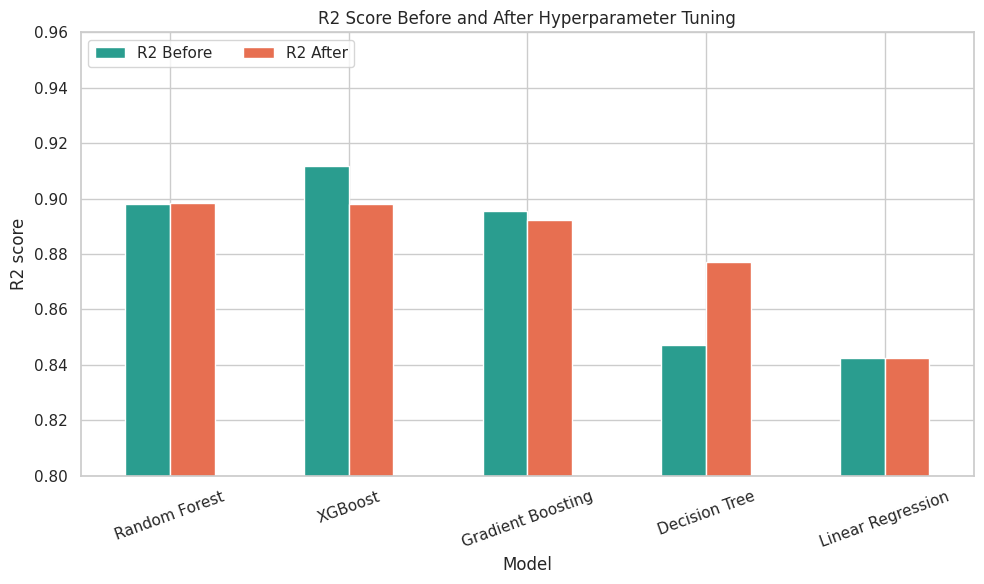

In [26]:
rows = []
for name, model in tuned.items():
    a = evaluate(y_test, model.predict(X_test))
    b = results_df.loc[name]
    rows.append({'Model': name,
                 'MAE Before': b['MAE'], 'MAE After': a['MAE'],
                 'RMSE Before': b['RMSE'], 'RMSE After': a['RMSE'],
                 'R2 Before': b['R2'], 'R2 After': a['R2'],
                 'MAPE Before': b['MAPE (%)'], 'MAPE After': a['MAPE (%)']})

tune_df = pd.DataFrame(rows).set_index('Model')
tune_df['R2 Change'] = tune_df['R2 After'] - tune_df['R2 Before']
tune_df['MAE Change (%)'] = (tune_df['MAE After'] - tune_df['MAE Before']) / tune_df['MAE Before'] * 100
tune_df = tune_df.sort_values('R2 After', ascending=False)
display(tune_df.style.format({'MAE Before': '{:,.0f}', 'MAE After': '{:,.0f}', 'RMSE Before': '{:,.0f}',
                              'RMSE After': '{:,.0f}', 'R2 Before': '{:.4f}', 'R2 After': '{:.4f}',
                              'MAPE Before': '{:.2f}', 'MAPE After': '{:.2f}',
                              'R2 Change': '{:+.4f}', 'MAE Change (%)': '{:+.1f}'}))
tune_df.to_csv(IMG + 'tuning_comparison.csv')

tune_df[['R2 Before', 'R2 After']].plot(kind='bar', figsize=(10, 6), color=['#2a9d8f', '#e76f51'])
plt.title('R2 Score Before and After Hyperparameter Tuning')
plt.xlabel('Model'); plt.ylabel('R2 score'); plt.ylim(0.8, 0.96)
plt.xticks(rotation=20); plt.legend(loc='upper left', ncol=2)
plt.tight_layout()
plt.savefig(IMG + 'tuning_r2_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:**
- **Decision Tree** improved the most: R² from 0.8473 to 0.8770 (+0.0297), MAE from 99,065 to 90,675 (-8.5%), RMSE from 190,415 to 170,872 and MAPE from 22.26% to 19.96%. Limiting its depth reduced the overfitting.
- **Random Forest** improved slightly: R² 0.8982 to 0.8984, MAE 79,016 to 78,273 (-0.9%) and MAPE 17.11% to 16.80%.
- **Gradient Boosting** has a lower MAE (84,103 to 80,165, -4.7%) and MAPE (17.68% to 16.70%), but a slightly lower R² (0.8954 to 0.8922) and a higher RMSE, which means that it became better for ordinary cars but a little worse for a few expensive ones.
- **XGBoost** did not improve: R² fell from 0.9118 to 0.8981, and MAE rose from 75,273 to 78,075 (+3.7%). Its default settings were already good, and the tuned model chosen by 3-fold cross-validation on the training data does not generalize better to this test set. The difference is small, and it is caused by only a few expensive cars, so it shows that tuning does not always improve a model that is already well set.
- **Linear Regression** has no tuned hyperparameters and stays unchanged.
- After tuning, the Random Forest (R² 0.8984) has the highest test R² and the lowest RMSE (155,296), followed closely by XGBoost (R² 0.8981, lowest MAE 78,075) and Gradient Boosting (R² 0.8922). The top three models are within 0.006 in R², so they are practically equal.

### 3.5 Feature Importance Analysis

Best tuned model: Random Forest


,0
max_power,0.7213
car_age,0.5310
engine,0.1198
km_driven,0.0463
transmission,0.0276
brand,0.0236
power_per_litre,0.0179
fuel,0.0086
mileage,0.0059
owner_num,0.0014


,0
num__car_age,0.4780
num__max_power,0.3094
num__engine,0.0794
num__mileage,0.0208
num__power_per_litre,0.0205
num__km_driven,0.0168
cat__brand_Tata,0.0141
num__km_per_year,0.0132
num__seats,0.0085
num__owner_num,0.0068


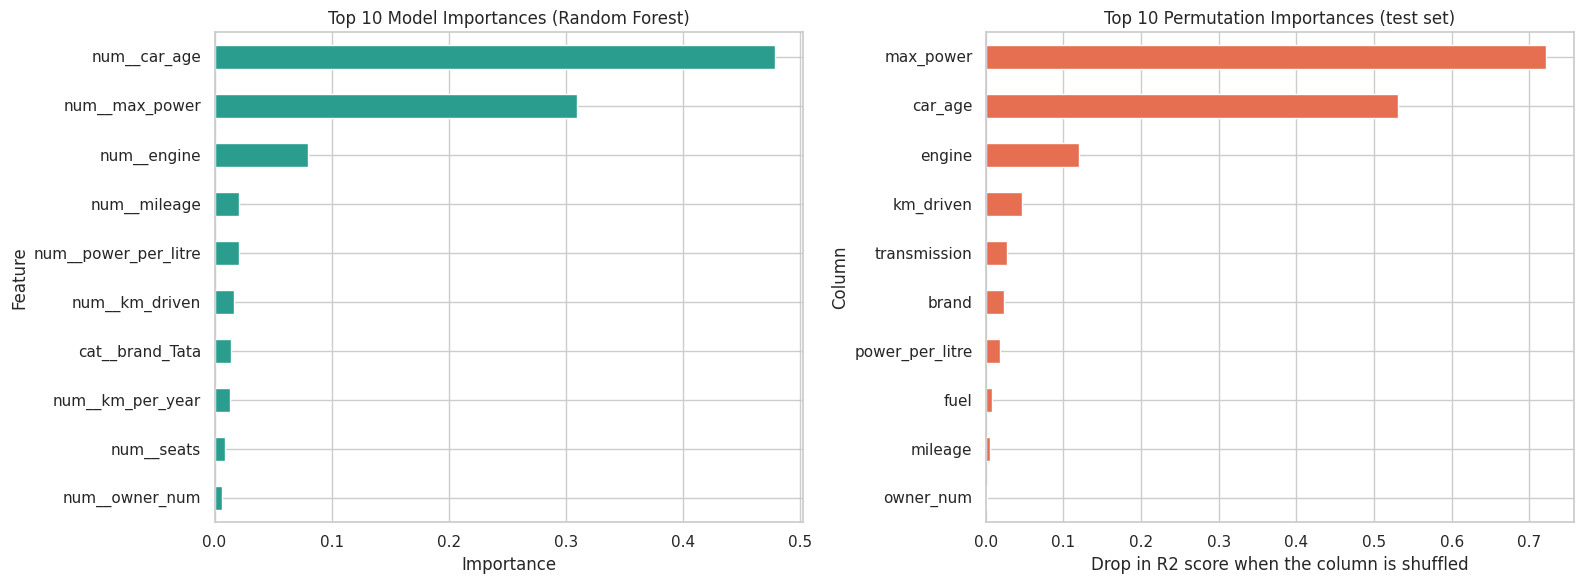

In [27]:
best_name = tune_df['R2 After'].idxmax()
best_model = tuned[best_name]
print("Best tuned model:", best_name)

perm = permutation_importance(best_model, X_test, y_test, scoring='r2', n_repeats=5,
                              random_state=42, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
display(perm_s.round(4))

inner = best_model.regressor_.named_steps['model']
feat_names = best_model.regressor_.named_steps['preprocess'].get_feature_names_out()
imp = pd.Series(inner.feature_importances_, index=feat_names).sort_values(ascending=False)
display(imp.head(10).round(4))

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
imp.head(10)[::-1].plot(kind='barh', color='#2a9d8f', ax=ax[0])
ax[0].set_title(f'Top 10 Model Importances ({best_name})')
ax[0].set_xlabel('Importance'); ax[0].set_ylabel('Feature')
perm_s.head(10)[::-1].plot(kind='barh', color='#e76f51', ax=ax[1])
ax[1].set_title('Top 10 Permutation Importances (test set)')
ax[1].set_xlabel('Drop in R2 score when the column is shuffled'); ax[1].set_ylabel('Column')
plt.tight_layout()
plt.savefig(IMG + 'feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation:**
- The best tuned model (by test R²) is the **Random Forest**. Its permutation importance shows that the car's **maximum power** (R² drops by 0.7213 when the column is shuffled) and its **age** (0.5310) are by far the most important inputs, followed by the **engine size** (0.1198) and the **kilometers driven** (0.0463). Transmission (0.0276), brand (0.0236), power per litre (0.0179) and fuel type (0.0086) have a smaller effect. The values do not add up to 1 because the columns work together and are correlated with each other.
- The model importance (left chart) agrees on the top three: car age (0.4780), maximum power (0.3094) and engine size (0.0794). It ranks the car age first because the trees use it for many splits, while the permutation importance ranks the maximum power first. The brand is spread over 32 separate 0/1 columns in the model importance (the largest is Tata with 0.0141), which hides its total effect; the permutation importance of the whole brand column (0.0236) shows it better.
- The engineered feature `power_per_litre` is useful (top 5 of the model importance with 0.0205, and 0.0179 in the permutation importance). `km_per_year` (-0.0008), `seller_type` (0.0000) and `seats` (0.0002) add practically nothing, which is expected because `km_per_year` is built from the kilometers and the age.
- These results agree with the correlations of Section 1.10 (maximum power 0.70, car age -0.44) and with common sense: a powerful, new car is expensive.

Two kinds of feature importance are shown for the best tuned model:
- **Model importance** (left): how much each encoded feature helped the trees to reduce the error during training. A categorical column such as the brand appears as several 0/1 columns.
- **Permutation importance** (right): each original column of the test set is shuffled in turn, and the drop in R² score is measured. A large drop means that the model depends strongly on this column. It is calculated on the raw columns, so it is easier to interpret, and it works on cars the model has not seen.

### 3.6 Prediction Range for the Application

In [28]:
cv_pred = cross_val_predict(best_model, X_train, y_train, cv=cv5, n_jobs=-1)
ratio = y_train.values / cv_pred                      # actual price divided by predicted price
q_low, q_high = np.quantile(ratio, [0.10, 0.90])
print("Range factors: lower =", round(q_low, 3), "| upper =", round(q_high, 3))

test_pred = best_model.predict(X_test)
inside = ((y_test.values >= test_pred * q_low) & (y_test.values <= test_pred * q_high)).mean()
print("Share of test cars whose real price lies inside the range:", round(inside * 100, 1), "%")

example = pd.DataFrame({'Predicted': [200000, 500000, 1000000, 2500000]})
example['Lower'] = (example['Predicted'] * q_low).round(-3)
example['Upper'] = (example['Predicted'] * q_high).round(-3)
display(example.style.format('{:,.0f}'))

Range factors: lower = 0.777 | upper = 1.28
Share of test cars whose real price lies inside the range: 79.3 %


,Predicted,Lower,Upper
0,"200,000","155,000","256,000"
1,"500,000","389,000","640,000"
2,"1,000,000","777,000","1,280,000"
3,"2,500,000","1,943,000","3,199,000"


**Observation:** The 10% and 90% quantiles of the ratio of the real to the predicted price are 0.777 and 1.28. A prediction is therefore shown with a range from 22% below to 28% above the predicted price. For example, a predicted price of 5 lakh rupees (500,000) is shown with a range of 3.89 to 6.40 lakh. The range was checked on the test set: the real price lies inside the range for 79.3% of the cars, very close to the intended 80%, so the range is well calibrated. The range grows with the price, which is realistic, because expensive cars are harder to predict.

A regression model gives one number, but the real price can be higher or lower. To show how reliable a prediction is (the regression counterpart of a prediction probability), a **prediction range** was calculated. The best model predicted the prices of the training cars with 5-fold cross-validation (every car is predicted by a model that has not seen it), and the ratio of the real price to the predicted price was calculated. The 10% and 90% quantiles of this ratio give a lower and an upper factor; multiplying a prediction by these factors gives a range in which the real price lies in about 80% of the cases. The range was then checked on the test set. It is stored with the model and shown in the application.

### 3.7 Selecting the Final Model
The **tuned Random Forest** is selected as the final model. After tuning it has the highest R² on the test set (0.8984), the lowest RMSE (155,296 rupees), an MAE of 78,273 rupees and a MAPE of 16.80%, and its prediction range is well calibrated (79.3% coverage). It also provides feature importance for the application. The tuned XGBoost (R² 0.8981, MAE 78,075) and the tuned Gradient Boosting (R² 0.8922) are practically as good, so the choice is not clear-cut; they remain available in the application through the multiple-model selection. One limitation of this choice is that it was made with the help of the test set; because the differences between the top models are very small, a different split could give a different order.

## 4. Model Saving
### 4.1 Saving the Final Model and the Other Tuned Models with Joblib

In [29]:
import joblib
import json
import sklearn
import xgboost

MODELS = '/content/drive/MyDrive/Task_04_AI_ML/models/'
os.makedirs(MODELS, exist_ok=True)

final_name = best_name                  # the model selected in Section 3.7
final_model = tuned[final_name]

file_names = {'Linear Regression': 'linear_regression.joblib', 'Decision Tree': 'decision_tree.joblib',
              'Random Forest': 'random_forest.joblib', 'Gradient Boosting': 'gradient_boosting.joblib',
              'XGBoost': 'xgboost.joblib'}

model_files, sizes = {}, {}
for name, model in tuned.items():
    fname = 'car_price_model.joblib' if name == final_name else file_names[name]
    if name == 'XGBoost':
        joblib.dump(model, MODELS + fname, compress=0, protocol=4)   # no compression: safest way to save XGBoost
    else:
        joblib.dump(model, MODELS + fname, compress=3)
    model_files[name] = fname
    sizes[name] = round(os.path.getsize(MODELS + fname) / 1024 / 1024, 2)

print("Final model:", final_name)
for name in model_files:
    print(f"  {name:20s} -> {model_files[name]:28s} {sizes[name]} MB")
print("scikit-learn:", sklearn.__version__, "| xgboost:", xgboost.__version__)

Final model: Random Forest
  Decision Tree        -> decision_tree.joblib         0.04 MB
  Random Forest        -> car_price_model.joblib       19.27 MB
  Gradient Boosting    -> gradient_boosting.joblib     0.12 MB
  XGBoost              -> xgboost.joblib               0.9 MB
  Linear Regression    -> linear_regression.joblib     0.0 MB
scikit-learn: 1.6.1 | xgboost: 3.4.1


**Observation:** The final model (the tuned Random Forest) was saved as `car_price_model.joblib` (19.27 MB). The other tuned models are much smaller (the exact sizes are printed above). The forest is large because it stores 300 trees with a depth of up to 20, which is the reason why its depth was limited during tuning. At 19 MB it is still small enough for GitHub and for an online application. The models were created with scikit-learn 1.6.1 and XGBoost 3.4.1, and the same versions must be installed when the application loads them.

The final model is saved with **Joblib** as `car_price_model.joblib`, and the other tuned models are saved in separate files so that the application can offer a model selection. Each saved object is the complete pipeline (imputation, scaling, encoding and the model) inside the target-transformation wrapper, so it accepts the raw features of a car and returns the price in rupees directly; no separate preprocessing code is needed. The files are compressed to keep them small (the XGBoost file is saved without compression and with pickle protocol 4, so that it also loads on other Python versions), and the library versions are printed because a saved model should be loaded with the same versions.

### 4.2 Loading the Saved Model and Verifying It

In [30]:
loaded = joblib.load(MODELS + 'car_price_model.joblib')
same = np.allclose(final_model.predict(X_test), loaded.predict(X_test))
print("Identical predictions after reloading:", same)
print({k: round(v, 4) for k, v in evaluate(y_test, loaded.predict(X_test)).items()})

# every saved model must reload and give the same predictions (a damaged file shows up here)
for name, fname in model_files.items():
    reloaded = joblib.load(MODELS + fname)
    ok = np.allclose(reloaded.predict(X_test), tuned[name].predict(X_test))
    print(f"{name:20s} {fname:28s} reload OK: {ok}")

start = time.time()
loaded.predict(X_test.iloc[[0]])
print("Time for one prediction:", round((time.time() - start) * 1000), "ms")

Identical predictions after reloading: True
{'MAE': 78273.2752, 'MSE': 24116919179.9614, 'RMSE': np.float64(155296.2304), 'R2': 0.8984, 'R2 (log price)': 0.9098, 'MAPE (%)': 16.8038}
Decision Tree        decision_tree.joblib         reload OK: True
Random Forest        car_price_model.joblib       reload OK: True
Gradient Boosting    gradient_boosting.joblib     reload OK: True
XGBoost              xgboost.joblib               reload OK: True
Linear Regression    linear_regression.joblib     reload OK: True
Time for one prediction: 41 ms


**Observation:** The reloaded model gives identical predictions to the original model (`True`) and reproduces the test metrics exactly (MAE 78,273, RMSE 155,296, R² 0.8984, MAPE 16.80%). A single prediction takes only a few dozen milliseconds, which is fast enough for an interactive application.

The saved file was loaded again and used to predict the test set. The predictions are identical to those of the original model and the metrics are the same, so the saving worked correctly and the model can be reused without retraining. All five saved model files were reloaded and checked in the same way, so no file is damaged. A single prediction takes only a few milliseconds, which is fast enough for an interactive application.

### 4.3 Predicting New Cars the Way the Application Does

In [31]:
def make_input(brand, year, km_driven, fuel, seller_type, transmission, owner,
               mileage, engine, max_power, seats):
    """Turns the values entered by a user into the columns the model expects."""
    car_age = REF_YEAR - year
    return pd.DataFrame([{
        'km_driven': km_driven, 'mileage': mileage, 'engine': engine, 'max_power': max_power,
        'seats': seats, 'car_age': car_age, 'km_per_year': round(km_driven / max(car_age, 1)),
        'power_per_litre': round(max_power / engine * 1000, 2), 'owner_num': owner_map[owner],
        'fuel': fuel, 'seller_type': seller_type, 'transmission': transmission, 'brand': brand}])

bmw = make_input('BMW', 2018, 40000, 'Diesel', 'Dealer', 'Automatic', 'First Owner', 16.0, 1995, 190, 5)
print("Same columns as the training data:", set(bmw.columns) == set(X.columns))

sample = X_test.sample(3, random_state=7)
cmp = pd.DataFrame({'Actual price': y_test.loc[sample.index]})
for name, m in tuned.items():
    cmp[name] = m.predict(sample).round(-3)
display(cmp.style.format('{:,.0f}'))

price = final_model.predict(bmw)[0]
print(f"Estimated price of the BMW example ({final_name}): {price:,.0f} rupees"
      f" (range {price * q_low:,.0f} to {price * q_high:,.0f})")

Same columns as the training data: True


,Actual price,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Linear Regression
3563,"400,000","250,000","259,000","249,000","238,000","303,000"
1261,"495,000","567,000","557,000","568,000","570,000","582,000"
6027,"140,000","148,000","206,000","205,000","206,000","224,000"


Estimated price of the BMW example (Random Forest): 3,777,013 rupees (range 2,936,148 to 4,833,388)


**Observation:**
- `make_input` produces exactly the same columns as the training data (`True`), so the application can use it directly.
- For the three test cars the tuned models give different estimates, and the errors of single cars can be large. Car 3563 (real price 400,000) was underestimated by all models (238,000 to 303,000), car 1261 (real price 495,000) was overestimated by 12% to 18% (557,000 to 582,000), and for car 6027 (real price 140,000) the models predicted 148,000 to 224,000, which is too high for most of them. The Decision Tree was closest in two of the three cases, but this is a coincidence on three cars; on the whole test set it is clearly the weakest tree-based model. This is why the application shows a prediction range and not only a single number.
- The example 2018 BMW diesel (40,000 km, automatic, first owner, 190 bhp) is estimated at about 37.8 lakh rupees (3,777,013) with a range of 29.4 to 48.3 lakh, which is a plausible price for such a car.

The function `make_input` does exactly what the Streamlit application will do: it takes the values a user enters (brand, year, kilometers, fuel, seller type, transmission, owner, mileage, engine, power and seats), calculates the engineered features (car age, kilometers per year, power per litre and the owner number) and returns one row with the columns the model expects. Three cars of the test set were predicted by all five tuned models and compared with their real prices, and a new example car (a 2018 BMW diesel) was predicted with the final model together with its prediction range.

## 5. Preparing the Application Files
### 5.1 Prediction Ranges and Model Information for the Application

In [32]:
# prediction range of every tuned model (80% range from cross-validated predictions)
range_info = {}
for name, m in tuned.items():
    cvp = cross_val_predict(m, X_train, y_train, cv=cv5, n_jobs=-1)
    lo, hi = np.quantile(y_train.values / cvp, [0.10, 0.90])
    tp = m.predict(X_test)
    cover = ((y_test.values >= tp * lo) & (y_test.values <= tp * hi)).mean()
    range_info[name] = {'lower_factor': round(float(lo), 4), 'upper_factor': round(float(hi), 4),
                        'test_coverage': round(float(cover), 4)}
    print(name, range_info[name])

metrics_after = {}
for name in tune_df.index:
    r = tune_df.loc[name]
    metrics_after[name] = {'mae': float(r['MAE After']), 'rmse': float(r['RMSE After']),
                           'r2': float(r['R2 After']), 'mape': float(r['MAPE After']),
                           'r2_before': float(r['R2 Before'])}

info = {
    'final_model': final_name,
    'model_files': model_files,
    'ref_year': REF_YEAR,
    'target': 'selling_price (Indian rupees)',
    'log_target': True,
    'metrics_after_tuning': metrics_after,
    'prediction_range': range_info,
    'best_params': {n: {k: (v.item() if hasattr(v, 'item') else v) for k, v in tune_info[n]['best_params'].items()}
                    for n in tune_info},
    'categories': {'brand': sorted(df['brand'].unique().tolist()),
                   'fuel': sorted(df['fuel'].unique().tolist()),
                   'seller_type': sorted(df['seller_type'].unique().tolist()),
                   'transmission': sorted(df['transmission'].unique().tolist()),
                   'owner': list(owner_map.keys())},
    'input_ranges': {'year_min': int(REF_YEAR - df['car_age'].max()), 'year_max': int(REF_YEAR),
                     'km_driven_max': int(df['km_driven'].max()),
                     'mileage': [float(df['mileage'].min()), float(df['mileage'].max())],
                     'engine': [int(df['engine'].min()), int(df['engine'].max())],
                     'max_power': [float(df['max_power'].min()), float(df['max_power'].max())],
                     'seats': [int(df['seats'].min()), int(df['seats'].max())]},
    'training_rows': int(len(X_train)), 'test_rows': int(len(X_test)),
    'sklearn_version': sklearn.__version__, 'xgboost_version': xgboost.__version__
}
with open(MODELS + 'model_info.json', 'w') as f:
    json.dump(info, f, indent=2, default=str)
print("model_info.json saved")

Decision Tree {'lower_factor': 0.7424, 'upper_factor': 1.3492, 'test_coverage': 0.7876}
Random Forest {'lower_factor': 0.7774, 'upper_factor': 1.2797, 'test_coverage': 0.7926}
Gradient Boosting {'lower_factor': 0.7813, 'upper_factor': 1.2765, 'test_coverage': 0.7854}
XGBoost {'lower_factor': 0.7805, 'upper_factor': 1.2717, 'test_coverage': 0.7905}
Linear Regression {'lower_factor': 0.7423, 'upper_factor': 1.3284, 'test_coverage': 0.776}
model_info.json saved


**Observation:** All five prediction ranges are close to the intended 80%: the real test price lies inside the range for 77.6% (Linear Regression) to 79.3% (Random Forest) of the cars. The ranges of the tree-based models are narrower than those of the Decision Tree and Linear Regression, which makes them more informative: the XGBoost range is the narrowest (factors 0.7805 to 1.2717, a width of 0.49), followed by Gradient Boosting (0.7813 to 1.2765) and the Random Forest (0.7774 to 1.2797), while the Decision Tree (0.7424 to 1.3492, a width of 0.61) and Linear Regression (0.7423 to 1.3284) have the widest ranges. A narrow range with the same coverage means a more precise model.

For every tuned model a prediction range was calculated in the same way as in Section 3.6, so the application can show a range for whichever model the user selects. The information file stores the final model, the model files, the ranges, the test metrics before and after tuning, the best hyperparameters, the lists of brands, fuel types, seller types and transmissions (used for the drop-down menus), the realistic input ranges taken from the data, the reference year used for the car age, and the library versions.

### 5.2 Saving the Result Tables for the Application

In [33]:
results_df.to_csv(MODELS + 'baseline_results.csv')
tune_df.to_csv(MODELS + 'tuning_comparison.csv')
cv_df.to_csv(MODELS + 'cross_validation_results.csv')
perm_s.rename('importance').to_csv(MODELS + 'permutation_importance.csv')
imp.rename('importance').to_csv(MODELS + 'model_importance.csv')

test_pred = pd.DataFrame({'actual_price': y_test.values})
for name, m in tuned.items():
    test_pred[name] = m.predict(X_test).round(0)
test_pred.to_csv(MODELS + 'test_predictions.csv', index=False)

for f in sorted(os.listdir(MODELS)):
    print(f"{f:35s} {round(os.path.getsize(MODELS + f) / 1024, 1):>10} KB")

baseline_results.csv                       0.8 KB
car_price_model.joblib                 19734.2 KB
cross_validation_results.csv               0.5 KB
decision_tree.joblib                      45.8 KB
gradient_boosting.joblib                 119.6 KB
linear_regression.joblib                   3.6 KB
model_importance.csv                       1.9 KB
model_info.json                            3.9 KB
permutation_importance.csv                 0.4 KB
test_predictions.csv                      70.9 KB
tuning_comparison.csv                      1.1 KB
xgboost.joblib                           918.5 KB


**Observation:** The `models` folder now contains everything the application needs: the final model, the four other tuned models, the information file (`model_info.json`), the result tables for the performance page and the test-set predictions of all models. The total size is about 20 MB, and most of it is the final Random Forest.

The comparison tables, the feature importance and the test-set predictions of all models were saved next to the models. The application uses them for its model performance page and its charts, so it does not need to recalculate anything. The final listing shows that all files needed by the application are in the `models` folder.

## 6. Conclusion

**Problem and data.** The goal was to build a working application that estimates the selling price of a used car from its details. The CarDekho dataset (8,128 cars, 13 columns) was used. The text columns with units (mileage, engine, power) were converted to numbers, 1,202 duplicates (14.79%), 5 test-drive cars and 3 cars with more than 500,000 km were removed, and impossible values (a mileage or power of 0) were set to missing. Outliers were analyzed with the IQR method; genuine luxury cars were kept. Five features were engineered (car age, brand, owner number, kilometers per year and power per litre), and the price was modeled on a log scale because it is strongly skewed (skewness 4.19, after the log transform 0.22). All preprocessing is combined in one pipeline that is fitted on the training data only.

**Models and tuning.** Five regression models were trained and compared with MAE, MSE, RMSE and R². With default settings XGBoost was the best (R² 0.9118, MAE 75,273 rupees), while the Decision Tree overfitted strongly (training R² 0.9992, test R² 0.8473). Cross-validation showed that the results depend on a few very expensive cars: Linear Regression had the best R² (0.9094), while the tree-based models had a lower MAE. Hyperparameter tuning (GridSearchCV and RandomizedSearchCV) improved the Decision Tree most (R² +0.0297), improved the Random Forest slightly, lowered the MAE of Gradient Boosting, and did not improve XGBoost (R² 0.9118 to 0.8981), whose default settings were already good. After tuning, the top three models are practically equal (R² 0.8984, 0.8981 and 0.8922).

**Final model and application.** The tuned **Random Forest** was selected as the final model (test R² 0.8984, MAE 78,273 rupees, RMSE 155,296 rupees, MAPE 16.80%). The most important inputs are the maximum power, the age of the car and the engine size. Because a single price can be wrong (a typical car is off by about 17%), a prediction range was added (about 22% below to 28% above the estimate), which contains the real price for 79.3% of the test cars. The final model and the four other tuned models were saved with Joblib together with their ranges, metrics and category lists, and these files are used by the Streamlit application, which offers prediction with a range, model selection, feature importance, data visualization and model performance pages.

**Limitations.** The data comes from one Indian website and is a snapshot (the newest cars are from 2020), so the prices do not follow the market of today and are not valid for other countries. Tree-based models cannot predict prices above the range they have seen, so very expensive cars are less reliable. Important information such as the car's condition, accident history and color is not available, and the model was only validated on a random split of the same data.